Raw Rows Loaded: 294,478
QA Flag - Mismatched Rows Removed: 3,893
Clean Unique Users Analyzed: 290,584

            Users  Conversions  Conv_Rate  CI_95_Low  CI_95_High
group                                                           
control    145274        17489     0.1204     0.1187      0.1221
treatment  145310        17264     0.1188     0.1171      0.1205

Control Conversion Rate:   12.04%
Treatment Conversion Rate: 11.88%
Relative Lift:             -1.31%
Z-Statistic: 1.311 | P-Value: 0.1899
Product Decision: DO NOT SHIP (No Statistically Significant Lift)


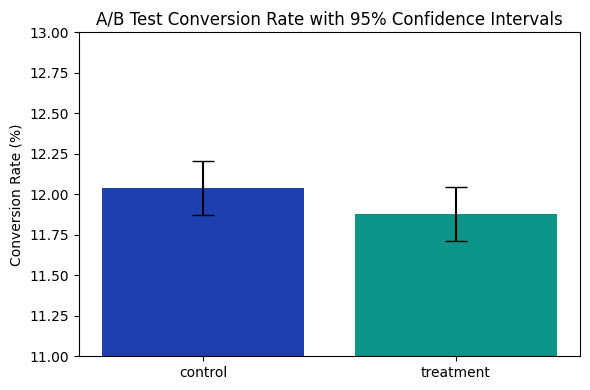

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

# 1. Load Raw Experiment Logs
ab = pd.read_csv('ab_data.csv')
print(f"Raw Rows Loaded: {len(ab):,}")

# 2. Data Quality QA: Remove group/landing_page mismatches & duplicate users
mismatches = ab[((ab['group'] == 'control') & (ab['landing_page'] != 'old_page')) |
                ((ab['group'] == 'treatment') & (ab['landing_page'] != 'new_page'))]
print(f"QA Flag - Mismatched Rows Removed: {len(mismatches):,}")

clean_ab = ab[((ab['group'] == 'control') & (ab['landing_page'] == 'old_page')) |
              ((ab['group'] == 'treatment') & (ab['landing_page'] == 'new_page'))].drop_duplicates('user_id')
print(f"Clean Unique Users Analyzed: {len(clean_ab):,}\n")

# 3. Conversion Summary & 95% Confidence Intervals
summary = clean_ab.groupby('group')['converted'].agg(Users='count', Conversions='sum', Conv_Rate='mean')
ci_low, ci_high = proportion_confint(count=summary['Conversions'], nobs=summary['Users'], alpha=0.05)
summary['CI_95_Low'] = ci_low
summary['CI_95_High'] = ci_high
print(summary.round(4))

# 4. Two-Proportion Z-Test (Hypothesis Test)
z_stat, p_val = proportions_ztest(count=summary['Conversions'], nobs=summary['Users'])
ctrl_rate = summary.loc['control', 'Conv_Rate']
treat_rate = summary.loc['treatment', 'Conv_Rate']
rel_lift = (treat_rate - ctrl_rate) / ctrl_rate

print(f"\nControl Conversion Rate:   {ctrl_rate:.2%}")
print(f"Treatment Conversion Rate: {treat_rate:.2%}")
print(f"Relative Lift:             {rel_lift:+.2%}")
print(f"Z-Statistic: {z_stat:.3f} | P-Value: {p_val:.4f}")
print("Product Decision:", "SHIP NEW PAGE (p < 0.05)" if p_val < 0.05 else "DO NOT SHIP (No Statistically Significant Lift)")

# 5. Export Clean Summary & Chart for GitHub
summary.to_csv('ab_test_results_summary.csv')
plt.figure(figsize=(6, 4))
plt.bar(summary.index, summary['Conv_Rate'] * 100, yerr=(summary['CI_95_High'] - summary['Conv_Rate']) * 100,
        capsize=8, color=['#1E40AF', '#0D9488'])
plt.ylabel('Conversion Rate (%)')
plt.title('A/B Test Conversion Rate with 95% Confidence Intervals')
plt.ylim(11, 13)
plt.tight_layout()
plt.savefig('ab_test_conversion_chart.png', dpi=300)
plt.show()